# 🏦 Sistem Prediksi Persetujuan Pinjaman (Loan Approval Prediction)
### Menggunakan Algoritma Decision Tree Classifier Berbasis Streamlit

**Bagian 1 — Google Colab**: pengolahan dataset, preprocessing, training, evaluasi, dan export model.

**Tujuan:** membangun model klasifikasi yang memprediksi apakah pengajuan pinjaman seorang nasabah akan
**Approved (Disetujui)** atau **Rejected (Ditolak)** berdasarkan data pemohon seperti pendapatan, jumlah pinjaman,
CIBIL score, pendidikan, jumlah tanggungan, dan nilai aset.

**Alur notebook:**
1. Import library → 2. Membaca dataset → 3. Informasi dataset → 4. EDA → 5. Distribusi target →
6. Missing value & duplikasi → 7. Data cleaning → 8. Preprocessing & encoding → 9. Pemisahan X dan y →
10. Train-test split 80:20 → 11. Training Decision Tree → 12. Evaluasi → 13. Confusion Matrix →
14. Classification Report → 15. Visualisasi Decision Tree → 16. Feature Importance → 17. Kesimpulan → 18. Export model

> Hasil akhir notebook ini adalah file `loan_approval_pipeline.pkl` dan `loan_model_metrics.json`
> yang dipakai oleh aplikasi Streamlit (`app.py`).

## 1. Import Library

In [ ]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

try:
    from IPython.display import display
except ImportError:          # jika dijalankan di luar Jupyter/Colab
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42            # agar hasil selalu sama setiap dijalankan
WARNA_APPROVED = "#2E9E5B"   # hijau
WARNA_REJECTED = "#D64545"   # merah
WARNA_NAVY = "#1F3A5F"       # navy blue

print("Versi scikit-learn:", sklearn.__version__)

Versi scikit-learn: 1.9.1


## 2. Upload dan Membaca Dataset

- **Di Google Colab:** jalankan sel di bawah, lalu pilih file `loan_approval_dataset.csv` dari komputer Anda.
- **Di komputer lokal (Jupyter/VS Code):** dataset dibaca otomatis dari folder `../dataset/`.

Model akan disimpan ke folder `models` (di Colab) atau `../models` (lokal).

In [ ]:
try:
    from google.colab import files          # hanya ada di Google Colab
    print("Silakan upload file loan_approval_dataset.csv")
    uploaded = files.upload()
    path_dataset = list(uploaded.keys())[0]
    OUTPUT_DIR = "models"
    DI_COLAB = True
except ImportError:                          # dijalankan secara lokal
    path_dataset = "../dataset/loan_approval_dataset.csv"
    OUTPUT_DIR = "../models"
    DI_COLAB = False

os.makedirs(OUTPUT_DIR, exist_ok=True)

df_raw = pd.read_csv(path_dataset)
print("Dataset dibaca dari :", path_dataset)
print("Nama kolom asli     :", df_raw.columns.tolist())
display(df_raw.head())

Dataset dibaca dari : ../dataset/loan_approval_dataset.csv
Nama kolom asli     : ['loan_id', ' no_of_dependents', ' education', ' self_employed', ' income_annum', ' loan_amount', ' loan_term', ' cibil_score', ' residential_assets_value', ' commercial_assets_value', ' luxury_assets_value', ' bank_asset_value', ' loan_status']
   loan_id   no_of_dependents  ...  bank_asset_value  loan_status
0        1                  2  ...           8000000     Approved
1        2                  0  ...           3300000     Rejected
2        3                  3  ...          12800000     Rejected
3        4                  3  ...           7900000     Rejected
4        5                  5  ...           5000000     Rejected

[5 rows x 13 columns]


**Temuan awal:** nama kolom dan nilai teks pada dataset asli memiliki **spasi di depan**
(contoh: `' education'` dan `' Graduate'`). Jika dibiarkan, pemanggilan `df['education']` akan error dan
kategori seperti `' Approved'` berbeda dengan `'Approved'`.
Spasi dirapikan di bawah ini. Langkah ini **tidak menghapus data**, hanya merapikan format.

In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip()                      # rapikan nama kolom

kolom_teks = ["education", "self_employed", "loan_status"]
for kolom in kolom_teks:
    df[kolom] = df[kolom].str.strip()                    # rapikan nilai teks

print("Nama kolom setelah dirapikan:", df.columns.tolist())
print("Nilai education    :", df["education"].unique().tolist())
print("Nilai self_employed:", df["self_employed"].unique().tolist())
print("Nilai loan_status  :", df["loan_status"].unique().tolist())

Nama kolom setelah dirapikan: ['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']
Nilai education    : ['Graduate', 'Not Graduate']
Nilai self_employed: ['No', 'Yes']
Nilai loan_status  : ['Approved', 'Rejected']


## 3. Informasi Dataset

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
print()
print("Tipe data tiap kolom:")
print(df.dtypes)
print()
df.info()

Jumlah baris : 4269
Jumlah kolom : 13

Tipe data tiap kolom:
loan_id                     int64
no_of_dependents            int64
education                     str
self_employed                 str
income_annum                int64
loan_amount                 int64
loan_term                   int64
cibil_score                 int64
residential_assets_value    int64
commercial_assets_value     int64
luxury_assets_value         int64
bank_asset_value            int64
loan_status                   str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amoun

**Statistik deskriptif** untuk kolom numerik:

In [ ]:
display(df.describe().T)

                           count          mean  ...         75%         max
loan_id                   4269.0  2.135000e+03  ...      3202.0      4269.0
no_of_dependents          4269.0  2.498712e+00  ...         4.0         5.0
income_annum              4269.0  5.059124e+06  ...   7500000.0   9900000.0
loan_amount               4269.0  1.513345e+07  ...  21500000.0  39500000.0
loan_term                 4269.0  1.090045e+01  ...        16.0        20.0
cibil_score               4269.0  5.999361e+02  ...       748.0       900.0
residential_assets_value  4269.0  7.472617e+06  ...  11300000.0  29100000.0
commercial_assets_value   4269.0  4.973155e+06  ...   7600000.0  19400000.0
luxury_assets_value       4269.0  1.512631e+07  ...  21700000.0  39200000.0
bank_asset_value          4269.0  4.976692e+06  ...   7100000.0  14700000.0

[10 rows x 8 columns]


## 4. Exploratory Data Analysis (EDA)

Tujuannya memahami bentuk data sebelum membuat model: sebaran tiap fitur, hubungan fitur kategorikal dengan
status pinjaman, dan korelasi antar fitur numerik.

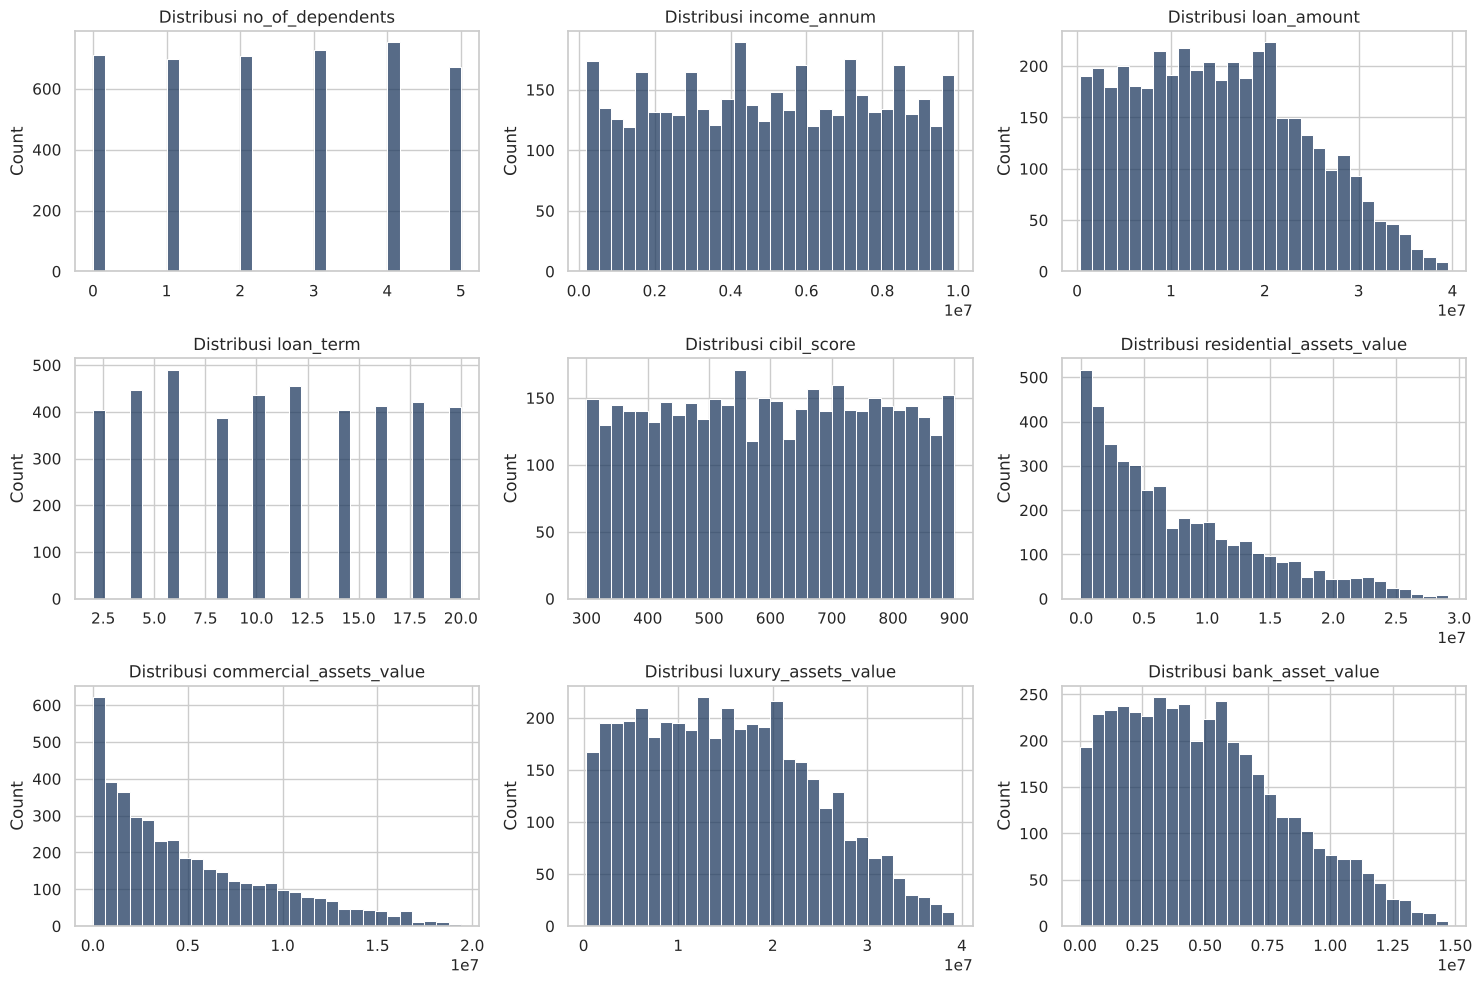

In [ ]:
kolom_aset = ["residential_assets_value", "commercial_assets_value",
              "luxury_assets_value", "bank_asset_value"]
kolom_numerik = ["no_of_dependents", "income_annum", "loan_amount", "loan_term",
                 "cibil_score"] + kolom_aset

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, kolom in zip(axes.ravel(), kolom_numerik):
    sns.histplot(df[kolom], bins=30, ax=ax, color=WARNA_NAVY)
    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**CIBIL score berdasarkan status pinjaman** — fitur yang biasanya paling menentukan keputusan kredit:

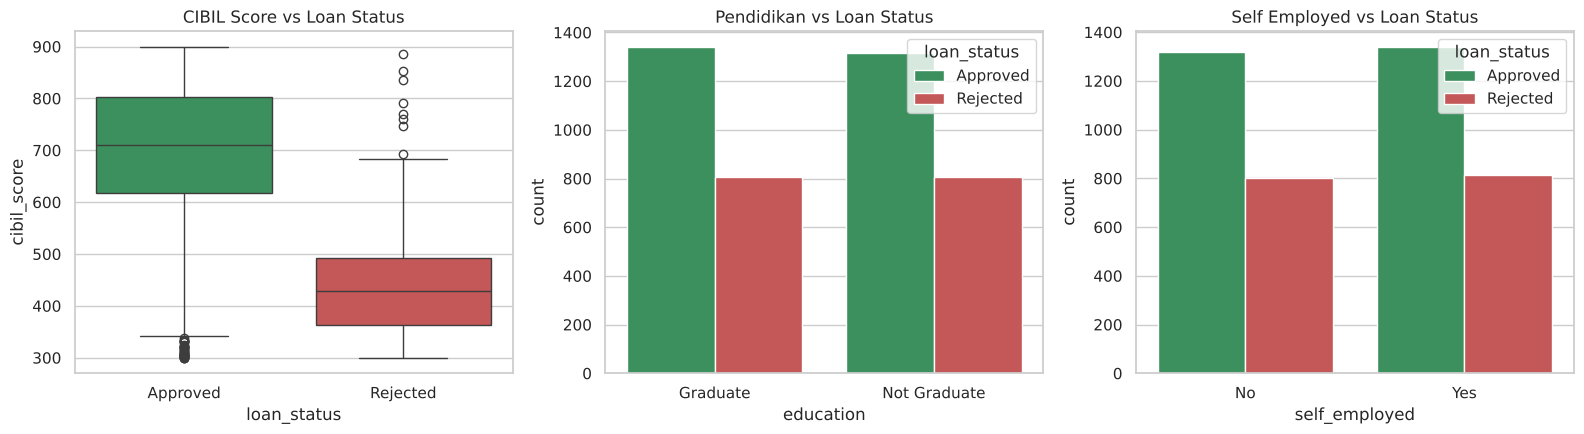

In [ ]:
warna = {"Approved": WARNA_APPROVED, "Rejected": WARNA_REJECTED}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="loan_status", y="cibil_score", palette=warna, ax=axes[0])
axes[0].set_title("CIBIL Score vs Loan Status")

sns.countplot(data=df, x="education", hue="loan_status", palette=warna, ax=axes[1])
axes[1].set_title("Pendidikan vs Loan Status")

sns.countplot(data=df, x="self_employed", hue="loan_status", palette=warna, ax=axes[2])
axes[2].set_title("Self Employed vs Loan Status")
plt.tight_layout()
plt.show()

**Korelasi antar fitur numerik** (termasuk status Approved = 1, Rejected = 0 hanya untuk keperluan EDA):

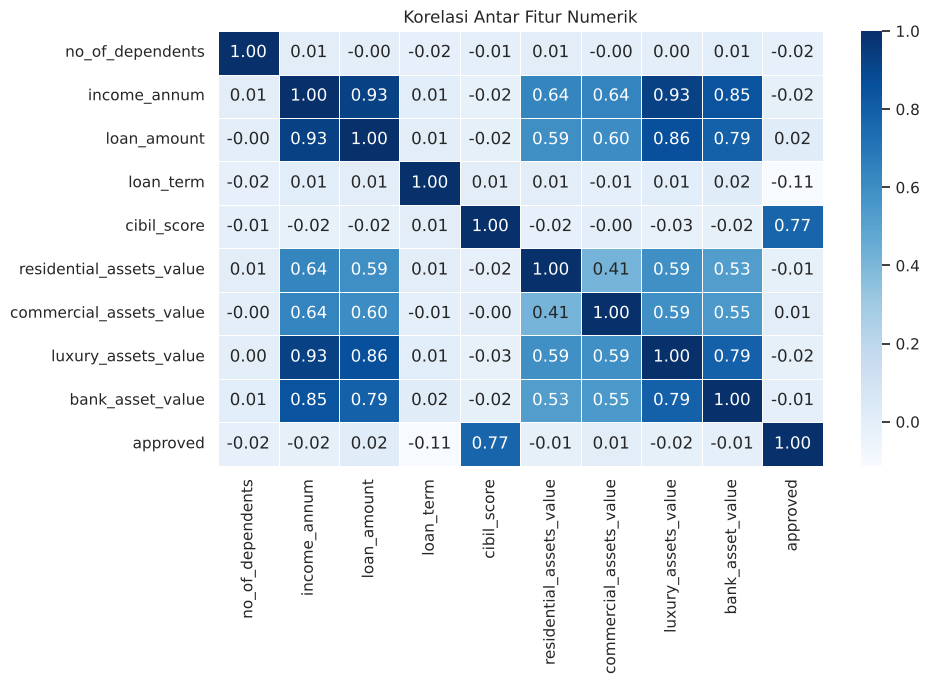

In [ ]:
df_korelasi = df[kolom_numerik].copy()
df_korelasi["approved"] = (df["loan_status"] == "Approved").astype(int)

plt.figure(figsize=(10, 7))
sns.heatmap(df_korelasi.corr(), annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Korelasi Antar Fitur Numerik")
plt.tight_layout()
plt.show()

## 5. Visualisasi Distribusi Target (`loan_status`)

             Jumlah  Persentase (%)
loan_status                        
Approved       2656           62.22
Rejected       1613           37.78


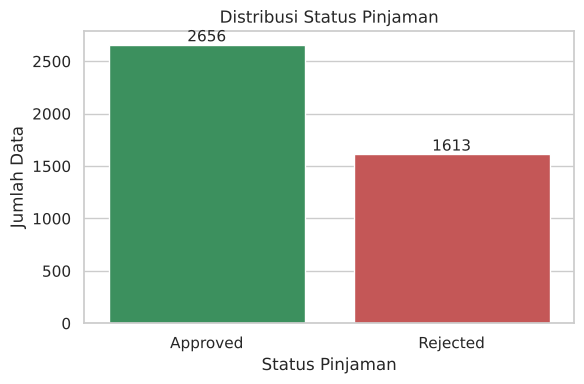

In [ ]:
jumlah = df["loan_status"].value_counts()
persen = df["loan_status"].value_counts(normalize=True) * 100
display(pd.DataFrame({"Jumlah": jumlah, "Persentase (%)": persen.round(2)}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="loan_status", order=["Approved", "Rejected"],
                   palette=[WARNA_APPROVED, WARNA_REJECTED])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
plt.title("Distribusi Status Pinjaman")
plt.xlabel("Status Pinjaman")
plt.ylabel("Jumlah Data")
plt.tight_layout()
plt.show()

**Interpretasi:** kelas *Approved* lebih banyak daripada *Rejected*, tetapi perbedaannya tidak ekstrem
(tidak sangat tidak seimbang). Karena itu tidak perlu oversampling/undersampling, cukup memakai
**stratified split** agar proporsi kelas pada data latih dan data uji tetap sama.

## 6. Pemeriksaan Missing Values dan Duplikasi

In [ ]:
print("Missing value per kolom:")
print(df.isnull().sum())
print()
print("Total missing value          :", df.isnull().sum().sum())
print("Jumlah baris duplikat        :", df.duplicated().sum())
print("Duplikat (tanpa kolom loan_id):", df.drop(columns=["loan_id"]).duplicated().sum())
print("loan_id unik semua?          :", df["loan_id"].is_unique)

Missing value per kolom:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Total missing value          : 0
Jumlah baris duplikat        : 0
Duplikat (tanpa kolom loan_id): 0
loan_id unik semua?          : True


**Interpretasi:** tidak ada missing value dan tidak ada data duplikat, sehingga tidak perlu imputasi
maupun penghapusan baris duplikat.

### Pemeriksaan Nilai Tidak Valid / Anomali

Dicek berdasarkan logika data: nilai aset dan pendapatan tidak boleh negatif, CIBIL score berada pada
rentang 300–900, jangka waktu pinjaman harus positif, dan kategori hanya berisi nilai yang dikenal.

In [ ]:
print("Nilai aset negatif per kolom:")
print((df[kolom_aset] < 0).sum())
print()
print("CIBIL di luar 300-900 :", ((df["cibil_score"] < 300) | (df["cibil_score"] > 900)).sum())
print("income_annum <= 0     :", (df["income_annum"] <= 0).sum())
print("loan_amount  <= 0     :", (df["loan_amount"] <= 0).sum())
print("loan_term    <= 0     :", (df["loan_term"] <= 0).sum())
print("no_of_dependents < 0  :", (df["no_of_dependents"] < 0).sum())
print()
print("Nilai aset negatif yang ditemukan:")
print(df.loc[df[kolom_aset].lt(0).any(axis=1), kolom_aset].stack().loc[lambda s: s < 0].value_counts())

Nilai aset negatif per kolom:
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64

CIBIL di luar 300-900 : 0
income_annum <= 0     : 0
loan_amount  <= 0     : 0
loan_term    <= 0     : 0
no_of_dependents < 0  : 0

Nilai aset negatif yang ditemukan:
-100000    28
Name: count, dtype: int64


**Temuan anomali:** terdapat sejumlah kecil baris dengan nilai aset **negatif**. Nilai aset secara logika
tidak mungkin negatif, sehingga dianggap kesalahan input. Nilainya sangat kecil dibanding skala data (jutaan),
dan baris tersebut masih memiliki informasi fitur lain yang valid. Maka **barisnya tidak dihapus**,
tetapi nilai negatif diubah menjadi 0.

## 7. Data Cleaning

Ringkasan keputusan cleaning beserta alasannya:

| Langkah | Tindakan | Alasan |
|---|---|---|
| Spasi pada nama kolom & nilai teks | Dirapikan dengan `strip()` | Mencegah error dan kategori ganda (sudah dilakukan di langkah 2) |
| Missing value | Tidak ada, tidak perlu tindakan | Data sudah lengkap |
| Data duplikat | Tidak ada, tidak perlu tindakan | — |
| Kolom `loan_id` | **Dihapus dari fitur** | Hanya nomor identitas, tidak punya makna prediktif; bisa membuat model menghafal urutan data |
| Nilai aset negatif | **Diubah menjadi 0** (baris tidak dihapus) | Aset tidak mungkin negatif; mempertahankan jumlah data |
| Outlier | Tidak dihapus | Decision Tree tidak sensitif terhadap outlier dan nilai ekstrem masih wajar secara logika |

In [ ]:
df_model = df.drop(columns=["loan_id"]).copy()
baris_sebelum = len(df_model)

for kolom in kolom_aset:
    jumlah_negatif = (df_model[kolom] < 0).sum()
    if jumlah_negatif > 0:
        print(f"{kolom}: {jumlah_negatif} nilai negatif diubah menjadi 0")
    df_model[kolom] = df_model[kolom].clip(lower=0)

print()
print("Jumlah baris sebelum cleaning :", baris_sebelum)
print("Jumlah baris sesudah cleaning :", len(df_model), "(tidak ada baris yang dihapus)")
print("Sisa nilai aset negatif       :", (df_model[kolom_aset] < 0).sum().sum())

residential_assets_value: 28 nilai negatif diubah menjadi 0

Jumlah baris sebelum cleaning : 4269
Jumlah baris sesudah cleaning : 4269 (tidak ada baris yang dihapus)
Sisa nilai aset negatif       : 0


## 8. Preprocessing dan Encoding Fitur Kategorikal

- **Fitur kategorikal** (`education`, `self_employed`) diubah menjadi angka dengan **One-Hot Encoding**
  (`drop='if_binary'` sehingga masing-masing hanya menjadi 1 kolom 0/1).
- **Fitur numerik** diteruskan apa adanya (*passthrough*). **Scaling tidak diperlukan** karena Decision Tree
  membagi data berdasarkan ambang batas (threshold), bukan jarak.
- Semua langkah dibungkus dalam `ColumnTransformer` dan `Pipeline`. Dengan begitu preprocessing **di-fit hanya
  pada data latih** (menghindari *data leakage*) dan **persis sama** saat dipakai oleh Streamlit untuk prediksi.

In [ ]:
fitur_kategorikal = ["education", "self_employed"]
fitur_numerik = ["no_of_dependents", "income_annum", "loan_amount", "loan_term", "cibil_score",
                 "residential_assets_value", "commercial_assets_value",
                 "luxury_assets_value", "bank_asset_value"]

preprocessor = ColumnTransformer(
    transformers=[
        ("kategorikal", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), fitur_kategorikal),
        ("numerik", "passthrough", fitur_numerik),
    ],
    verbose_feature_names_out=False,
)
print("Preprocessor siap (belum di-fit, akan di-fit di dalam Pipeline setelah data dibagi).")

Preprocessor siap (belum di-fit, akan di-fit di dalam Pipeline setelah data dibagi).


## 9. Pemisahan Fitur (X) dan Target (y)

In [ ]:
fitur = [k for k in df_model.columns if k != "loan_status"]   # urutan sama dengan dataset
X = df_model[fitur]
y = df_model["loan_status"]

print("Fitur (X):", fitur)
print("Bentuk X :", X.shape)
print("Bentuk y :", y.shape)

Fitur (X): ['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Bentuk X : (4269, 11)
Bentuk y : (4269,)


## 10. Train-Test Split (80:20, Stratified)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Data latih (train):", X_train.shape[0], "baris")
print("Data uji   (test) :", X_test.shape[0], "baris")
print()
perbandingan = pd.DataFrame({
    "Seluruh data (%)": (y.value_counts(normalize=True) * 100).round(2),
    "Train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True) * 100).round(2),
})
display(perbandingan)

Data latih (train): 3415 baris
Data uji   (test) : 854 baris

             Seluruh data (%)  Train (%)  Test (%)
loan_status                                       
Approved                62.22      62.23     62.18
Rejected                37.78      37.77     37.82


Proporsi kelas pada data latih dan uji sama dengan data asli, artinya *stratify* bekerja dengan benar.

Berikut contoh hasil preprocessing (di-fit **hanya pada data latih** pada salinan preprocessor,
hanya untuk melihat bentuk hasil encoding):

In [ ]:
contoh = clone(preprocessor)
hasil = contoh.fit_transform(X_train)
display(pd.DataFrame(hasil, columns=contoh.get_feature_names_out()).head())

   education_Not Graduate  ...  bank_asset_value
0                     0.0  ...         7200000.0
1                     1.0  ...         5200000.0
2                     1.0  ...         1300000.0
3                     1.0  ...         4600000.0
4                     1.0  ...         1300000.0

[5 rows x 11 columns]


## 11. Training Model Decision Tree Classifier

Pipeline = `preprocessor` → `DecisionTreeClassifier`.

Agar pohon tidak terlalu rumit (overfitting), dua pengaturan dipilih dengan
**GridSearchCV 5-fold cross validation pada data latih saja**: kedalaman maksimum (`max_depth`) dan jumlah
minimum sampel pada tiap daun (`min_samples_leaf`). Data uji tidak disentuh sampai tahap evaluasi,
sehingga tidak terjadi data leakage.

In [ ]:
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

param_grid = {
    "classifier__max_depth": [5, 6, 8, 10, None],
    "classifier__min_samples_leaf": [1, 3, 5, 10, 20],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)

hasil_cv = pd.DataFrame({
    "max_depth": [str(p["classifier__max_depth"]) for p in grid.cv_results_["params"]],
    "min_samples_leaf": [p["classifier__min_samples_leaf"] for p in grid.cv_results_["params"]],
    "Akurasi CV (rata-rata)": grid.cv_results_["mean_test_score"].round(4),
}).sort_values("Akurasi CV (rata-rata)", ascending=False).reset_index(drop=True)
print("5 kombinasi terbaik:")
display(hasil_cv.head(5))

model_terbaik = grid.best_estimator_            # Pipeline lengkap yang sudah dilatih
print("max_depth terbaik       :", grid.best_params_["classifier__max_depth"])
print("min_samples_leaf terbaik:", grid.best_params_["classifier__min_samples_leaf"])
print("Akurasi CV terbaik    :", round(grid.best_score_, 4))

5 kombinasi terbaik:
  max_depth  min_samples_leaf  Akurasi CV (rata-rata)
0        10                 5                  0.9813
1      None                 5                  0.9807
2        10                10                  0.9795
3        10                 3                  0.9792
4      None                 1                  0.9786
max_depth terbaik       : 10
min_samples_leaf terbaik: 5
Akurasi CV terbaik    : 0.9813


## 12. Evaluasi Model (pada Data Uji)

In [ ]:
y_pred = model_terbaik.predict(X_test)

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall    = recall_score(y_test, y_pred, average="weighted")
f1        = f1_score(y_test, y_pred, average="weighted")
akurasi_train = accuracy_score(y_train, model_terbaik.predict(X_train))

hasil_evaluasi = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (weighted)", "Recall (weighted)", "F1-Score (weighted)"],
    "Nilai": [accuracy, precision, recall, f1],
})
display(hasil_evaluasi.round(4))
print(f"Akurasi data latih : {akurasi_train:.4f}")
print(f"Akurasi data uji   : {accuracy:.4f}")

                 Metrik   Nilai
0              Accuracy  0.9789
1  Precision (weighted)  0.9790
2     Recall (weighted)  0.9789
3   F1-Score (weighted)  0.9789
Akurasi data latih : 0.9874
Akurasi data uji   : 0.9789


**Catatan:** Precision, Recall, dan F1 memakai rata-rata *weighted* (dibobot jumlah data tiap kelas).
Nilai per kelas (Approved dan Rejected) ada pada Classification Report di bawah.
Perbandingan akurasi latih dan uji dipakai untuk memeriksa apakah model overfitting.
Probabilitas pada Decision Tree dihitung dari proporsi kelas pada daun tempat data jatuh, sehingga banyak
data yang probabilitasnya tepat 100%/0% (daun murni).

## 13. Confusion Matrix

Approved diprediksi benar (TP)        : 526
Approved salah diprediksi Rejected (FN): 5
Rejected salah diprediksi Approved (FP): 13
Rejected diprediksi benar (TN)        : 310


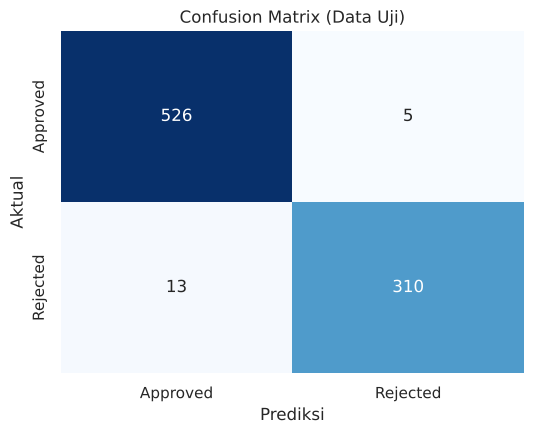

In [ ]:
label = ["Approved", "Rejected"]
cm = confusion_matrix(y_test, y_pred, labels=label)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label, yticklabels=label, cbar=False)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix (Data Uji)")
plt.tight_layout()
plt.show()

print(f"Approved diprediksi benar (TP)        : {cm[0][0]}")
print(f"Approved salah diprediksi Rejected (FN): {cm[0][1]}")
print(f"Rejected salah diprediksi Approved (FP): {cm[1][0]}")
print(f"Rejected diprediksi benar (TN)        : {cm[1][1]}")

## 14. Classification Report

In [ ]:
print(classification_report(y_test, y_pred, labels=label, digits=4))

              precision    recall  f1-score   support

    Approved     0.9759    0.9906    0.9832       531
    Rejected     0.9841    0.9598    0.9718       323

    accuracy                         0.9789       854
   macro avg     0.9800    0.9752    0.9775       854
weighted avg     0.9790    0.9789    0.9789       854



## 15. Visualisasi Decision Tree

Agar mudah dibaca, yang ditampilkan hanya **3 level teratas** pohon (pohon aslinya lebih dalam).
Setiap kotak berisi: aturan pemisahan, nilai gini, jumlah sampel, jumlah tiap kelas, dan kelas mayoritas.

Kedalaman pohon sebenarnya : 10
Jumlah daun (leaf)         : 31


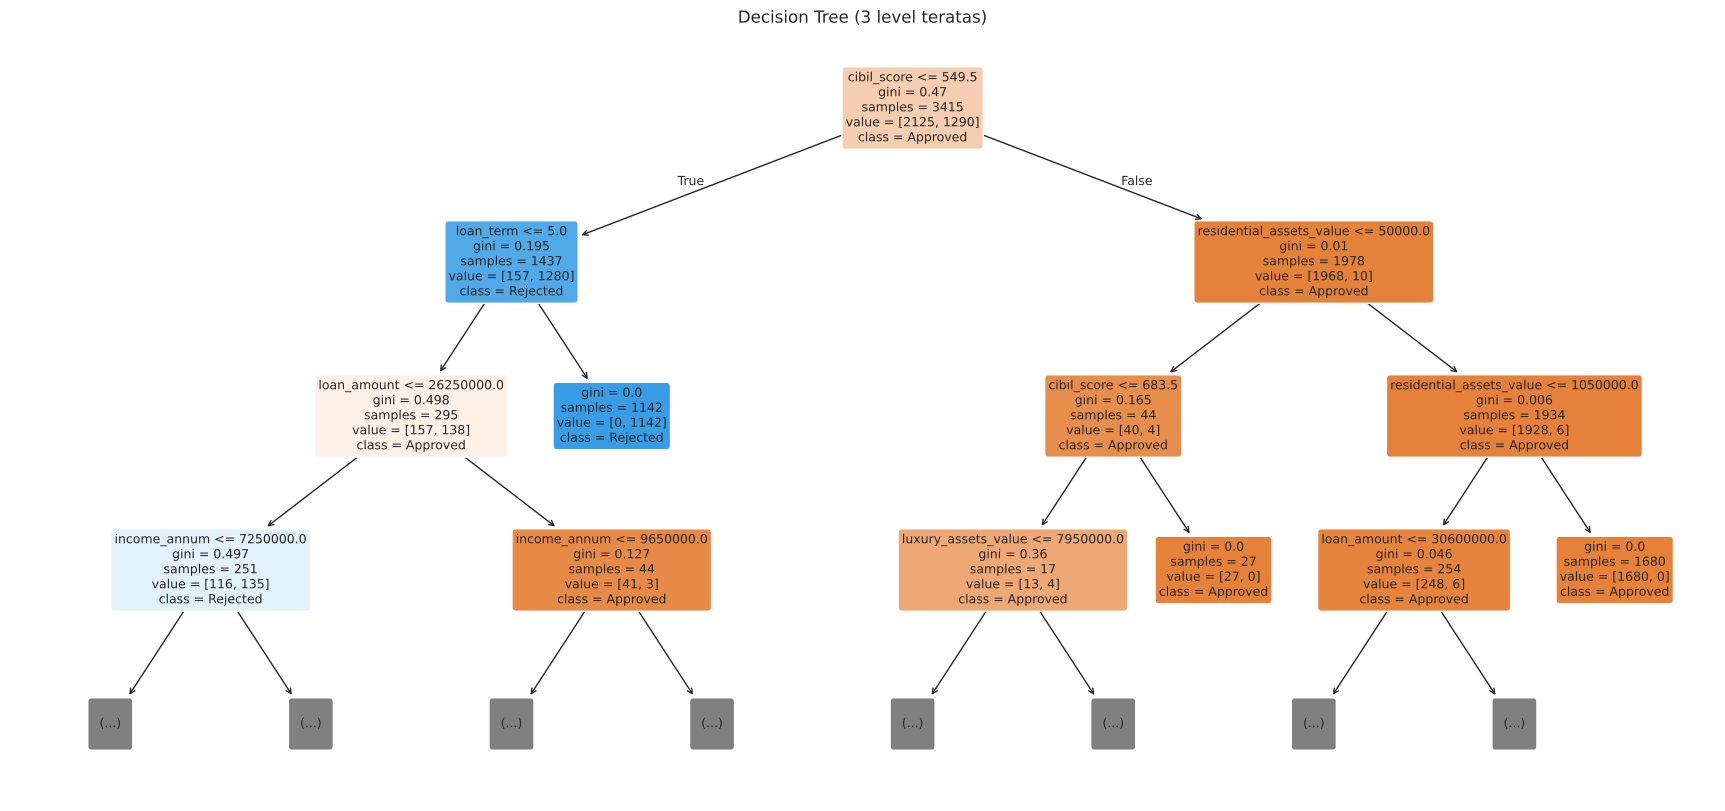

In [ ]:
klasifikasi = model_terbaik.named_steps["classifier"]
nama_fitur = model_terbaik.named_steps["preprocessor"].get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(klasifikasi, max_depth=3, feature_names=nama_fitur, class_names=list(klasifikasi.classes_),
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (3 level teratas)")
plt.show()

print("Kedalaman pohon sebenarnya :", klasifikasi.get_depth())
print("Jumlah daun (leaf)         :", klasifikasi.get_n_leaves())

## 16. Feature Importance

                       Fitur  Importance
0                cibil_score      0.8454
1                  loan_term      0.0858
2                loan_amount      0.0295
3               income_annum      0.0193
4        luxury_assets_value      0.0092
5    commercial_assets_value      0.0084
6          self_employed_Yes      0.0015
7   residential_assets_value      0.0010
8     education_Not Graduate      0.0000
9           no_of_dependents      0.0000
10          bank_asset_value      0.0000


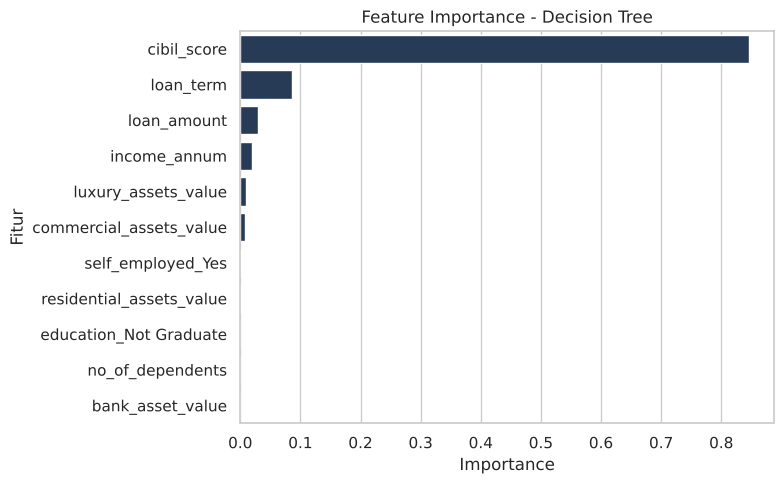

In [ ]:
importance = pd.DataFrame({
    "Fitur": nama_fitur,
    "Importance": klasifikasi.feature_importances_,
}).sort_values("Importance", ascending=False).reset_index(drop=True)
display(importance.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x="Importance", y="Fitur", color=WARNA_NAVY)
plt.title("Feature Importance - Decision Tree")
plt.tight_layout()
plt.show()

## 17. Kesimpulan Hasil Klasifikasi

In [ ]:
fitur_utama = importance.iloc[0]["Fitur"]
print("KESIMPULAN")
print("-" * 60)
print(f"1. Dataset berisi {len(df)} data pemohon, dibagi menjadi {len(X_train)} data latih dan {len(X_test)} data uji (80:20).")
print(f"2. Model Decision Tree (max_depth = {grid.best_params_['classifier__max_depth']}, min_samples_leaf = {grid.best_params_['classifier__min_samples_leaf']}) mencapai akurasi {accuracy*100:.2f}% pada data uji.")
print(f"3. Precision = {precision*100:.2f}%, Recall = {recall*100:.2f}%, F1-Score = {f1*100:.2f}% (rata-rata weighted).")
print(f"4. Akurasi data latih {akurasi_train*100:.2f}% vs data uji {accuracy*100:.2f}% -> selisih {abs(akurasi_train-accuracy)*100:.2f} poin.")
print(f"5. Fitur paling berpengaruh: {fitur_utama} (importance = {importance.iloc[0]['Importance']:.4f}).")
print(f"6. Dari {len(y_test)} data uji, {cm[0][1] + cm[1][0]} diprediksi salah ({cm[0][1]} Approved->Rejected, {cm[1][0]} Rejected->Approved).")
print("-" * 60)
print("Catatan: hasil ini hanya untuk tujuan edukasi, bukan keputusan kredit yang sebenarnya.")

KESIMPULAN
------------------------------------------------------------
1. Dataset berisi 4269 data pemohon, dibagi menjadi 3415 data latih dan 854 data uji (80:20).
2. Model Decision Tree (max_depth = 10, min_samples_leaf = 5) mencapai akurasi 97.89% pada data uji.
3. Precision = 97.90%, Recall = 97.89%, F1-Score = 97.89% (rata-rata weighted).
4. Akurasi data latih 98.74% vs data uji 97.89% -> selisih 0.85 poin.
5. Fitur paling berpengaruh: cibil_score (importance = 0.8454).
6. Dari 854 data uji, 18 diprediksi salah (5 Approved->Rejected, 13 Rejected->Approved).
------------------------------------------------------------
Catatan: hasil ini hanya untuk tujuan edukasi, bukan keputusan kredit yang sebenarnya.


## 18. Export Model untuk Streamlit

Dua file disimpan:
- `loan_approval_pipeline.pkl` — Pipeline (preprocessing + Decision Tree) dalam **satu file**.
- `loan_model_metrics.json` — metrik evaluasi, confusion matrix, feature importance, dan informasi dataset
  yang dibaca oleh halaman Dashboard dan Evaluasi pada Streamlit.

Semua angka pada JSON berasal dari hasil training dan testing di atas.

In [ ]:
path_model = os.path.join(OUTPUT_DIR, "loan_approval_pipeline.pkl")
path_metrik = os.path.join(OUTPUT_DIR, "loan_model_metrics.json")

# 1) Simpan pipeline (preprocessing + model)
joblib.dump(model_terbaik, path_model, compress=3)

# 2) Siapkan metrik untuk Streamlit
laporan = classification_report(y_test, y_pred, labels=label, output_dict=True)

metrik = {
    "dataset": {
        "nama_file": "loan_approval_dataset.csv",
        "jumlah_baris": int(len(df)),
        "jumlah_kolom_asli": int(df.shape[1]),
        "jumlah_fitur": int(len(fitur)),
        "fitur": fitur,
        "distribusi_kelas": {k: int(v) for k, v in y.value_counts().items()},
    },
    "split": {
        "test_size": 0.2,
        "random_state": RANDOM_STATE,
        "jumlah_train": int(len(X_train)),
        "jumlah_test": int(len(X_test)),
        "distribusi_train": {k: int(v) for k, v in y_train.value_counts().items()},
        "distribusi_test": {k: int(v) for k, v in y_test.value_counts().items()},
    },
    "model": {
        "algoritma": "Decision Tree Classifier",
        "max_depth": None if grid.best_params_["classifier__max_depth"] is None else int(grid.best_params_["classifier__max_depth"]),
        "min_samples_leaf": int(grid.best_params_["classifier__min_samples_leaf"]),
        "akurasi_cross_validation": float(grid.best_score_),
        "kedalaman_pohon": int(klasifikasi.get_depth()),
        "jumlah_daun": int(klasifikasi.get_n_leaves()),
        "sklearn_version": sklearn.__version__,
    },
    "metrics": {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1_score": float(f1),
        "average": "weighted",
        "akurasi_train": float(akurasi_train),
    },
    "classification_report": laporan,
    "confusion_matrix": {"labels": label, "matrix": cm.tolist()},
    "feature_importance": [
        {"feature": str(r.Fitur), "importance": float(r.Importance)} for r in importance.itertuples()
    ],
    "feature_ranges": {
        k: {"min": int(X[k].min()), "max": int(X[k].max()), "median": int(X[k].median())}
        for k in fitur_numerik
    },
    "kategori": {
        "education": sorted(X["education"].unique().tolist()),
        "self_employed": sorted(X["self_employed"].unique().tolist()),
    },
}

with open(path_metrik, "w", encoding="utf-8") as f:
    json.dump(metrik, f, indent=2, ensure_ascii=False)

print("Model disimpan   :", path_model, f"({os.path.getsize(path_model)/1024:.1f} KB)")
print("Metrik disimpan  :", path_metrik)

Model disimpan   : ../models/loan_approval_pipeline.pkl (3.3 KB)
Metrik disimpan  : ../models/loan_model_metrics.json


**Uji ulang:** muat kembali file `.pkl` lalu prediksi beberapa data uji untuk memastikan model yang tersimpan berfungsi.

In [ ]:
model_muat = joblib.load(path_model)
contoh_data = X_test.head(5)
probabilitas = model_muat.predict_proba(contoh_data)

hasil_uji = contoh_data[["cibil_score", "income_annum", "loan_amount"]].copy()
hasil_uji["Aktual"] = y_test.head(5).values
hasil_uji["Prediksi"] = model_muat.predict(contoh_data)
for i, kelas in enumerate(model_muat.classes_):
    hasil_uji[f"P({kelas})"] = probabilitas[:, i].round(3)
display(hasil_uji)

print("Prediksi model yang dimuat sama dengan model di memori?",
      bool((model_muat.predict(X_test) == y_pred).all()))

      cibil_score  income_annum  ...  P(Approved) P(Rejected)
2346          890       8000000  ...          1.0         0.0
1162          620       1900000  ...          1.0         0.0
3061          896       3300000  ...          1.0         0.0
483           538       2500000  ...          0.0         1.0
2102          771       7900000  ...          1.0         0.0

[5 rows x 7 columns]
Prediksi model yang dimuat sama dengan model di memori? True


In [ ]:
# Khusus Google Colab: unduh kedua file lalu letakkan di folder models/ pada project Streamlit
if DI_COLAB:
    files.download(path_model)
    files.download(path_metrik)
else:
    print("Dijalankan lokal: file sudah tersimpan langsung di folder models/.")

Dijalankan lokal: file sudah tersimpan langsung di folder models/.


---
✅ **Selesai.** Letakkan `loan_approval_pipeline.pkl` dan `loan_model_metrics.json` di folder `models/`,
lalu jalankan aplikasi Streamlit dengan `streamlit run app.py`.